# CryptoGuard++ | Elliptic Bitcoin Dataset — Exploratory Data Analysis

**Milestone 1 · Day 2 | Dataset and Graph Pipeline**

## Research objective

Investigate the statistical and structural properties of the original Elliptic Bitcoin Dataset before developing tabular, graph-based and hybrid classifiers for illicit transaction detection.

The analysis addresses three questions:
- How do label availability, class imbalance and transaction volume vary over time?
- What feature redundancy and graph connectivity patterns are present?
- Do labeled neighbors exhibit meaningful class agreement beyond that expected from class imbalance?

## Analysis outline

1. Environment and dataset setup
2. Data preparation and quality assessment
3. Class distribution and imbalance
4. Temporal analysis and evaluation protocol
5. Feature analysis
6. Graph topology
7. Homophily and heterophily
8. Research findings and next steps

**Evaluation boundary:** Full-dataset statistics are descriptive only. Model-design analyses use time steps 1–29. Validation (30–34) is reserved for model selection and test (35–49) for final evaluation. Do not use test statistics to tune preprocessing, architecture or thresholds. A stricter blind evaluation should withhold test-label summaries until final reporting.

**Dataset source:** [Elliptic Bitcoin Dataset](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set). Raw CSVs are stored locally under `data/raw/elliptic/` and are not committed to GitHub.

## 1. Environment and dataset setup
### 1.1 Import dependencies
Use the project's `.venv` interpreter as the notebook kernel. The analysis relies on NumPy, Pandas, Matplotlib, Seaborn and SciPy; no model training is performed here.

In [23]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)

sns.set_theme(style="whitegrid")

### 1.2 Locate the dataset
Resolve the project directory before reading the CSV files. This supports running the notebook from the notebook directory, the Python project root, or the outer Git repository.

In [24]:
required_files = (
    "elliptic_txs_features.csv",
    "elliptic_txs_edgelist.csv",
    "elliptic_txs_classes.csv",
)

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
ROOT = next(
    (p for base in candidates for p in (base, base / "cryptoguard")
     if all((p / "data" / "raw" / "elliptic" / f).is_file()
            for f in required_files)),
    None
)
if ROOT is None:
    raise FileNotFoundError("Place all three CSVs in data/raw/elliptic/ inside the project.")

DATA_DIR = ROOT / "data" / "raw" / "elliptic"
print("Dataset directory:", DATA_DIR.relative_to(ROOT))
print("Dataset exists:", DATA_DIR.exists())

Dataset directory: data\raw\elliptic
Dataset exists: True


### 1.3 Load the three CSV files
The feature file has no header and contains a transaction identifier, a time step and 165 numeric features. The edge list represents directed transaction relationships, and the class file records licit, illicit or unknown labels.

In [25]:
features = pd.read_csv(
    DATA_DIR / "elliptic_txs_features.csv",
    header=None
)

edges = pd.read_csv(
    DATA_DIR / "elliptic_txs_edgelist.csv"
)

classes = pd.read_csv(
    DATA_DIR / "elliptic_txs_classes.csv",
    dtype={"class": str}
)

print("Features:", features.shape)
print("Edges:", edges.shape)
print("Classes:", classes.shape)

Features: (203769, 167)
Edges: (234355, 2)
Classes: (203769, 2)


## 2. Data preparation and quality assessment
### 2.1 Assign feature names
Use neutral feature identifiers because the public dataset anonymizes most feature meanings. Keep transaction IDs and time steps separate from the numeric model features.

In [26]:
features.columns = ["txId", "time_step"] + [f"feature_{i}" for i in range(1, 166)]
features.head()

,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_156,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


### 2.2 Align features and labels
Join by `txId`, not row position. A one-to-one merge protects against duplicate IDs and misaligned labels. Keep the edge list separate until graph construction.

In [27]:
df = features.merge(
    classes,
    on="txId",
    how="left",
    validate="one_to_one"
)

assert len(df) == len(features)
assert df["class"].notna().all()

print("Merged dataset:", df.shape)

df.head()

Merged dataset: (203769, 168)


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165,class
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,unknown
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,2
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,unknown


### 2.3 Encode class labels
Use a consistent internal convention throughout CryptoGuard++.

| Original class | Encoded label | Meaning |
|---|---:|---|
| `1` | 1 | Illicit |
| `2` | 0 | Licit |
| `unknown` | -1 | Unlabeled |

Unknown nodes are not negative examples. They are excluded from supervised loss and evaluation but may provide graph context if the information is available under the evaluation protocol.

In [28]:
label_mapping = {
    "1": 1,
    "2": 0,
    "unknown": -1
}

df["label"] = df["class"].map(label_mapping)

assert df["label"].notna().all()

df["label"] = df["label"].astype("int64")

print(df["label"].value_counts())

df[["txId", "time_step", "class", "label"]].head()

label
-1    157205
 0     42019
 1      4545
Name: count, dtype: int64


,txId,time_step,class,label
0,230425980,1,unknown,-1
1,5530458,1,unknown,-1
2,232022460,1,unknown,-1
3,232438397,1,2,0
4,230460314,1,unknown,-1


### 2.4 Check data quality
Check missing and infinite values, duplicate identifiers and constant numeric features. These checks describe the released data; they do not automatically remove or modify any feature.

In [29]:
feature_cols = [
    f"feature_{i}" for i in range(1, 166)
]

X = df[feature_cols]

quality_report = pd.Series({
    "Total transactions": len(df),
    "Missing values": df.isna().sum().sum(),
    "Duplicate transaction IDs": df["txId"].duplicated().sum(),
    "Infinite feature values": np.isinf(X.to_numpy()).sum(),
    "Constant features": (X.nunique() <= 1).sum()
})

display(quality_report)

Total transactions           203769
Missing values                    0
Duplicate transaction IDs         0
Infinite feature values           0
Constant features                 0
dtype: int64

### 2.5 Inspect feature statistics
Summarize feature distributions with means, standard deviations and quantiles. The saved output shows examples with means near zero and standard deviations near one, consistent with prior normalization in the released data. This is not evidence that normalization was fitted on the training period only. Any new preprocessing must be fitted on training data, and the provenance of the supplied features must be acknowledged.

In [30]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
feature_1,203769.0,-8.926723e-18,1.000002,-0.172983,-0.172532,-0.169204,-0.131855,71.681966
feature_2,203769.0,0.000000e+00,1.000002,-0.210553,-0.180327,-0.132897,-0.055242,73.595052
feature_3,203769.0,3.570689e-17,1.000002,-1.756361,-1.201369,0.463609,1.018602,2.683580
feature_4,203769.0,9.205683e-18,1.000002,-0.121970,-0.121970,-0.121970,-0.121970,49.027598
feature_5,203769.0,1.227424e-17,1.000002,-0.063725,-0.043875,-0.043875,-0.043875,260.090707
...,...,...,...,...,...,...,...,...
feature_161,203769.0,-6.695042e-18,1.000002,-0.125939,-0.087490,-0.087490,-0.087490,251.849028
feature_162,203769.0,4.463361e-18,1.000002,-0.131155,-0.131155,-0.131155,-0.084674,238.783493
feature_163,203769.0,-1.785345e-17,1.000002,-0.269818,-0.140597,-0.097524,-0.097524,105.734028
feature_164,203769.0,-1.115840e-17,1.000002,-1.760926,-0.120613,-0.120613,0.152007,1.519700


## 3. Class distribution and imbalance
### 3.1 Distribution of all transactions
Measure label availability before excluding unknown nodes from supervised learning.

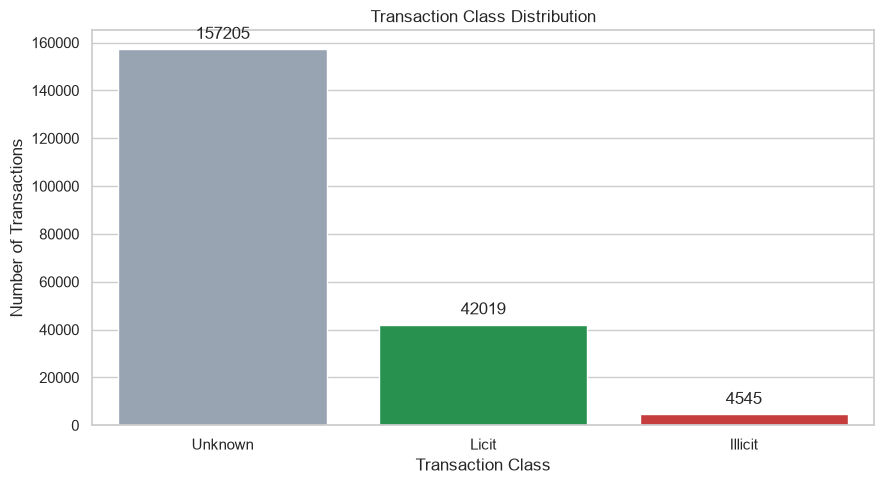

In [31]:
class_names = {
    -1: "Unknown",
    0: "Licit",
    1: "Illicit"
}

class_counts = (
    df["label"]
    .map(class_names)
    .value_counts()
    .reindex(["Unknown", "Licit", "Illicit"])
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=["#94a3b8", "#16a34a", "#dc2626"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=5, fmt="%d")

plt.title("Transaction Class Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

### 3.2 Distribution among labeled transactions
Exclude unknown labels from the denominator to quantify the imbalance relevant to supervised binary classification.

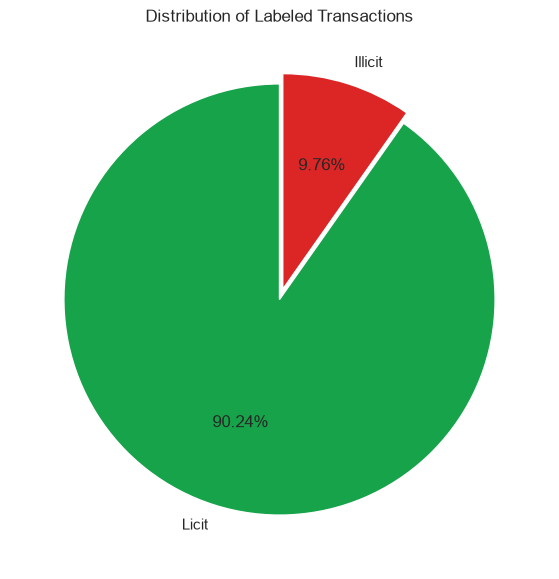

In [32]:
labeled_df = df[df["label"] != -1].copy()

labeled_counts = (
    labeled_df["label"]
    .map(class_names)
    .value_counts()
)

plt.figure(figsize=(7, 7))

plt.pie(
    labeled_counts.values,
    labels=labeled_counts.index,
    autopct="%1.2f%%",
    colors=["#16a34a", "#dc2626"],
    startangle=90,
    explode=[0, 0.05]
)

plt.title("Distribution of Labeled Transactions")
plt.show()

### 3.3 Imbalance ratio
Compute the number of licit transactions per illicit transaction. This full-dataset ratio is descriptive; class weights for model training must be estimated from the training partition only.

In [33]:
n_licit = (df["label"] == 0).sum()
n_illicit = (df["label"] == 1).sum()

imbalance_ratio = n_licit / n_illicit

print(f"Licit transactions: {n_licit:,}")
print(f"Illicit transactions: {n_illicit:,}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

Licit transactions: 42,019
Illicit transactions: 4,545
Imbalance ratio: 9.25:1


### Finding 01 — Limited supervision and class imbalance
The saved results show 157,205 unknown, 42,019 licit and 4,545 illicit transactions. Approximately 77.15% of nodes are unlabeled, and illicit transactions represent 9.76% of labeled nodes (a licit-to-illicit ratio of 9.25:1).

An always-licit classifier would achieve about 90.24% accuracy on the full labeled dataset while detecting no illicit transactions. Prioritize illicit-class F1, precision, recall and PR-AUC in subsequent experiments.

## 4. Temporal analysis and evaluation protocol
### 4.1 Transaction volume over time
Count transactions at each of the 49 discrete time steps. Variation in graph size may affect evaluation stability and computational requirements.

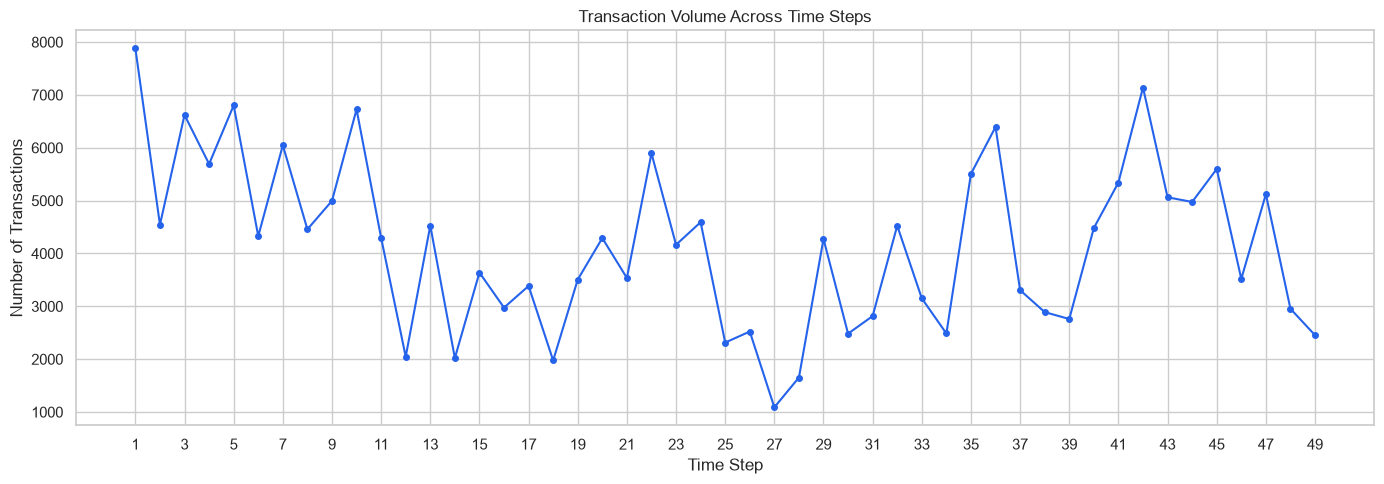

In [34]:
transactions_per_step = (
    df.groupby("time_step")
    .size()
    .sort_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    transactions_per_step.index,
    transactions_per_step.values,
    marker="o",
    markersize=4,
    color="#2563eb"
)

plt.title("Transaction Volume Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")
plt.xticks(range(1, 50, 2))
plt.tight_layout()
plt.show()

In [35]:
df.groupby("time_step").size()

time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
36    6393
37    3306
38    2891
39    2760
40    4481
41    5342
42    7140
43    5063
44    4975
45    5598
46    3519
47    5121
48    2954
49    2454
dtype: int64

### 4.2 Class distribution over time
Group transactions by time step and class, then visualize their counts. Retain all three classes so that changes in label coverage remain visible.

In [36]:
temporal_counts = (
    df.groupby(["time_step", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=range(1, 50),
        columns=[-1, 0, 1],
        fill_value=0
    )
    .rename(columns=class_names)
)

temporal_counts.head()

label,Unknown,Licit,Illicit
time_step,,,
1,5733,2130,17
2,3427,1099,18
3,5342,1268,11
4,4253,1410,30
5,4921,1874,8


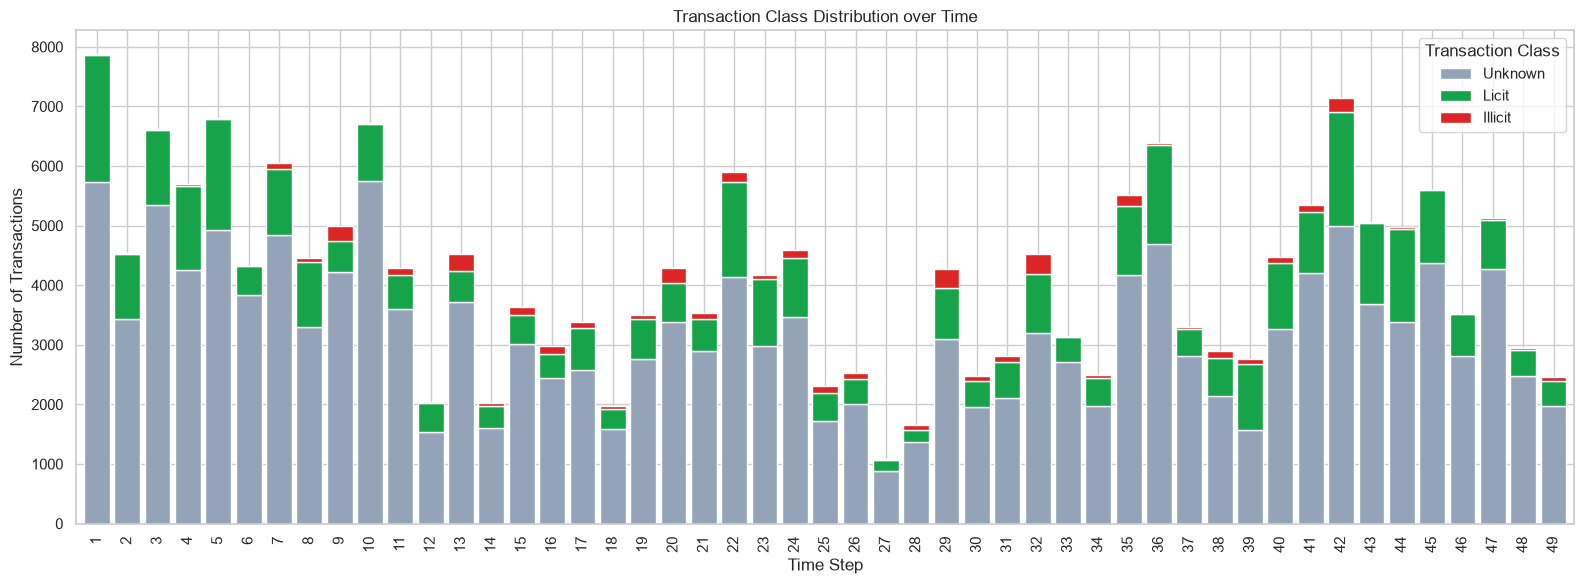

In [37]:
temporal_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 6),
    color=["#94a3b8", "#16a34a", "#dc2626"],
    width=0.85
)

plt.title("Transaction Class Distribution over Time")
plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")
plt.legend(title="Transaction Class")
plt.tight_layout()
plt.show()

### 4.3 Illicit rate and label coverage over time
Compute the illicit proportion among labeled transactions, as well as the fraction of transactions with any known label. A varying observed illicit rate indicates changing labeled-class prevalence, but does not establish concept drift or the prevalence among all transactions.

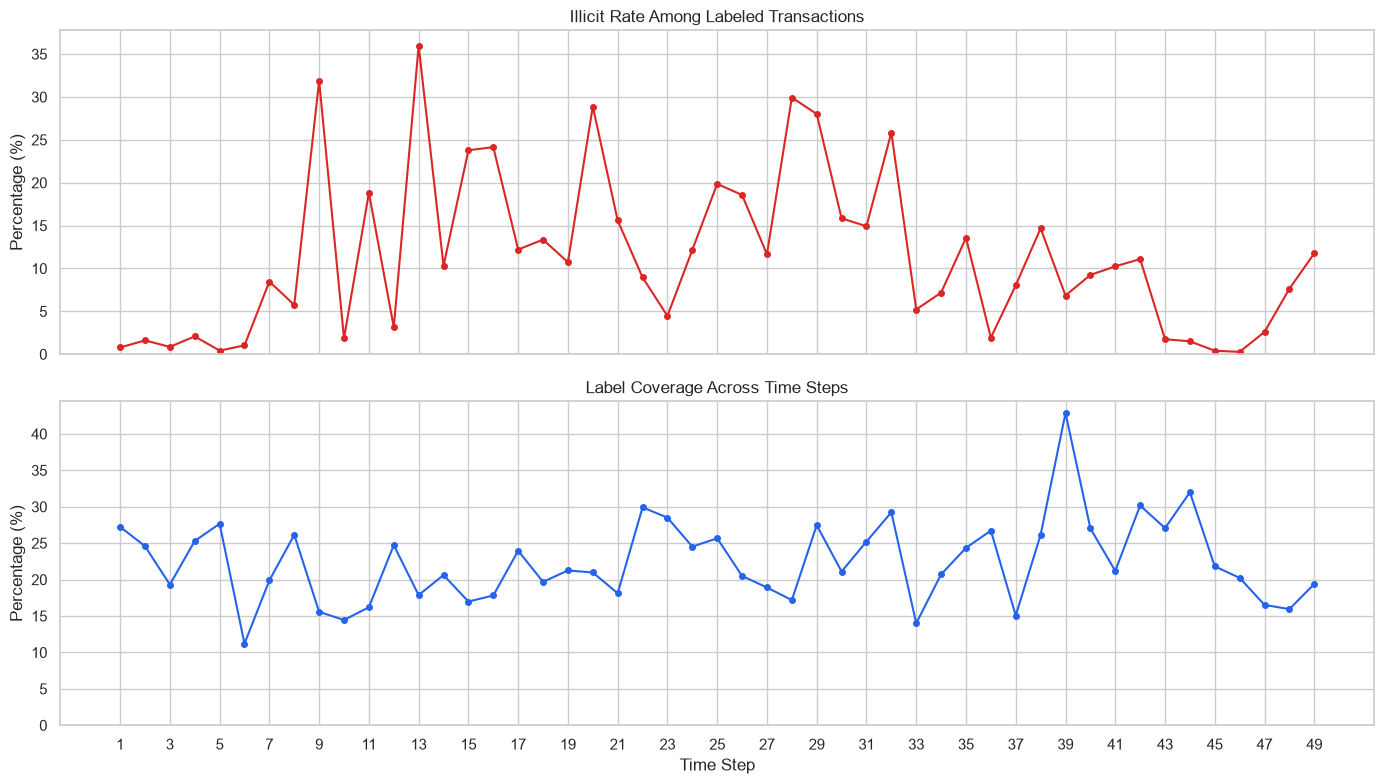

In [38]:
temporal_counts["Labeled"] = temporal_counts["Licit"] + temporal_counts["Illicit"]
temporal_counts["Illicit_rate"] = (
    temporal_counts["Illicit"] / temporal_counts["Labeled"].replace(0, np.nan)
)
temporal_counts["Label_coverage"] = (
    temporal_counts["Labeled"] / transactions_per_step.reindex(temporal_counts.index).replace(0, np.nan)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, col, title, color in [
    (axes[0], "Illicit_rate", "Illicit Rate Among Labeled Transactions", "#dc2626"),
    (axes[1], "Label_coverage", "Label Coverage Across Time Steps", "#2563eb"),
]:
    ax.plot(temporal_counts.index, temporal_counts[col] * 100, marker="o", markersize=4, color=color)
    ax.set_title(title)
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(bottom=0)
axes[-1].set_xlabel("Time Step")
axes[-1].set_xticks(range(1, 50, 2))
plt.tight_layout()
plt.show()

### 4.4 Inspect the proposed chronological split
Use the predefined CryptoGuard++ split: training 1–29, validation 30–34 and test 35–49. The table is a descriptive audit of this proposed protocol, not a basis for selecting a model or changing the test period. Unknown transactions remain in each graph partition but are excluded from supervised masks.

In [39]:
conditions = [
    df["time_step"] <= 29,
    df["time_step"].between(30, 34),
    df["time_step"] >= 35
]

choices = ["Train", "Validation", "Test"]

df["split"] = np.select(
    conditions,
    choices,
    default="Invalid"
)

split_summary = pd.crosstab(
    df["split"],
    df["label"]
).reindex(
    index=["Train", "Validation", "Test"],
    columns=[-1, 0, 1],
    fill_value=0
).rename(columns=class_names)

split_summary["Total"] = split_summary.sum(axis=1)

split_summary["Illicit_rate"] = (
    split_summary["Illicit"]
    / (
        split_summary["Licit"]
        + split_summary["Illicit"]
    ).replace(0, np.nan)
)

display(split_summary)

label,Unknown,Licit,Illicit,Total,Illicit_rate
split,,,,,
Train,94423,23510,2871,120804,0.108828
Validation,11948,2922,591,15461,0.168232
Test,50834,15587,1083,67504,0.064967


### Finding 02 — Temporal variation
The saved split summary contains 120,804 training nodes, 15,461 validation nodes and 67,504 test nodes. Observed illicit proportions among labeled transactions are 10.88%, 16.82% and 6.50%, respectively. These differences motivate chronological evaluation and per-period reporting. They do not establish concept drift, and the unknown labels prevent estimation of the true illicit prevalence.

## 5. Feature analysis
### 5.1 Local and aggregated features
After removing the time step, the numeric input contains 93 local features and 72 neighborhood-aggregated features. The latter already encode some graph information and may include forward-looking information within a snapshot. Compare local-only and full-feature baselines under a clearly stated information-availability assumption.

In [40]:
local_features = [
    f"feature_{i}"
    for i in range(1, 94)
]

aggregated_features = [
    f"feature_{i}"
    for i in range(94, 166)
]

print("Local features:", len(local_features))
print("Aggregated features:", len(aggregated_features))

assert len(local_features) == 93
assert len(aggregated_features) == 72

Local features: 93
Aggregated features: 72


### 5.2 Pearson correlation — training period
Calculate the linear correlation matrix using only training-period nodes. Correlation can reveal redundancy but does not establish causality or prove that a feature is unnecessary.

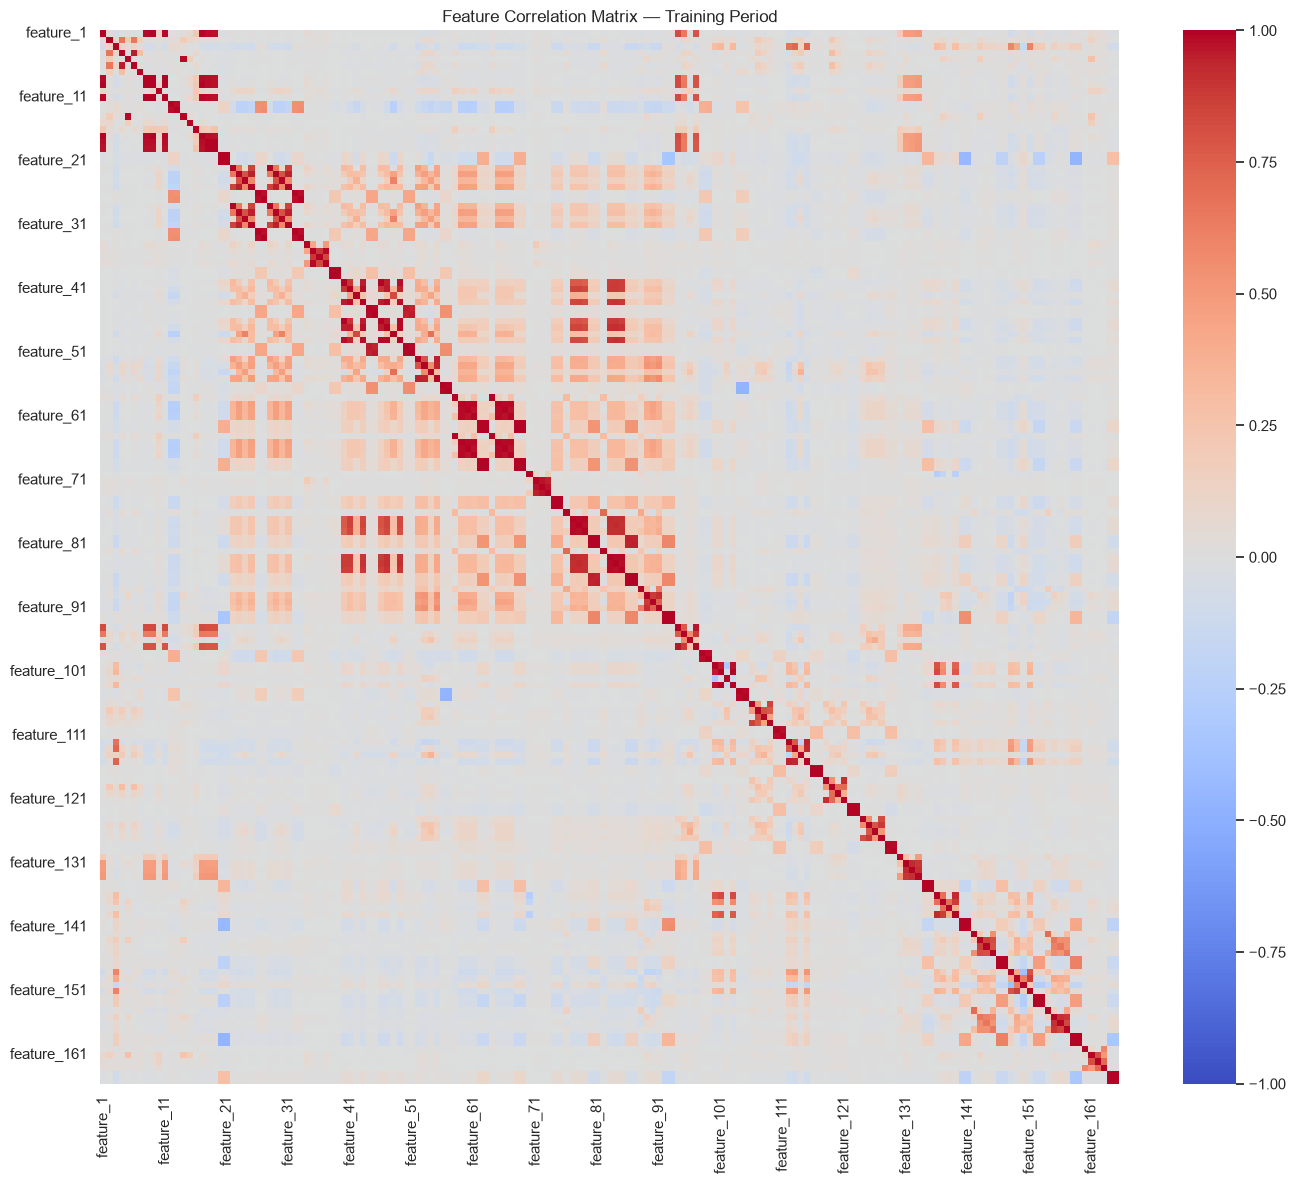

In [41]:
train_df = df[df["time_step"] <= 29]

corr_matrix = train_df[feature_cols].corr()

plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=10,
    yticklabels=10
)

plt.title("Feature Correlation Matrix — Training Period")
plt.tight_layout()
plt.show()

### 5.3 Highly correlated feature pairs
Inspect unique feature pairs with absolute Pearson correlation above 0.95. Use the upper triangle to avoid counting symmetric pairs twice or including self-correlations.

In [42]:
upper_triangle = corr_matrix.abs().where(
    np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1
    )
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs > 0.95
]

print(
    "Number of highly correlated feature pairs:",
    len(high_corr_pairs)
)

display(high_corr_pairs.head(20))

Number of highly correlated feature pairs: 104


feature_24   feature_30     1.000000
feature_22   feature_28     1.000000
feature_23   feature_29     1.000000
feature_25   feature_31     1.000000
feature_61   feature_67     1.000000
feature_60   feature_66     1.000000
feature_59   feature_65     1.000000
feature_58   feature_64     1.000000
feature_26   feature_32     0.999454
feature_27   feature_33     0.999439
feature_8    feature_11     0.999380
feature_152  feature_153    0.999336
feature_1    feature_17     0.997288
feature_62   feature_68     0.997091
feature_9    feature_17     0.997020
feature_63   feature_69     0.996983
feature_1    feature_9      0.996967
feature_158  feature_159    0.996961
feature_92   feature_93     0.996945
feature_74   feature_75     0.996906
dtype: float64

### Finding 03 — Feature redundancy
The saved training-period output identifies 104 feature pairs with absolute Pearson correlation greater than 0.95. Several are nearly perfectly correlated. Retain the original features for the initial baselines and evaluate any feature-selection strategy separately using training and validation data only.

## 6. Graph topology analysis
Analyze the released directed graph without adding self-loops, reverse edges or dropping unknown nodes. Whole-graph structural summaries are descriptive. Label-dependent comparisons for model design are restricted to the training period.

### 6.1 Transaction ID mapping
Map each original transaction ID to a contiguous node index. The order of `df` defines the order of features, labels and node indices. Do not reorder `df` after creating this mapping without rebuilding the graph.

In [43]:
num_nodes = len(df)
assert df["txId"].is_unique

tx_to_idx = {tx_id: idx for idx, tx_id in enumerate(df["txId"])}
idx_to_tx = df["txId"].to_numpy()

assert len(tx_to_idx) == num_nodes
print("Number of nodes:", num_nodes)
print("Mapping size:", len(tx_to_idx))

Number of nodes: 203769
Mapping size: 203769


### 6.2 Directed edge index
Convert source and destination transaction IDs to contiguous indices. Each column of `edge_index` represents one directed edge in the PyTorch Geometric convention.

In [44]:
source_col, target_col = "txId1", "txId2"
assert {source_col, target_col}.issubset(edges.columns), edges.columns.tolist()

src = edges[source_col].map(tx_to_idx)
dst = edges[target_col].map(tx_to_idx)
assert src.notna().all() and dst.notna().all()

src = src.to_numpy(dtype=np.int64)
dst = dst.to_numpy(dtype=np.int64)
edge_index = np.stack([src, dst])

assert edge_index.shape == (2, len(edges))
assert edge_index.min() >= 0 and edge_index.max() < num_nodes
assert np.array_equal(idx_to_tx[src], edges[source_col].to_numpy())
assert np.array_equal(idx_to_tx[dst], edges[target_col].to_numpy())

print("Edge index shape:", edge_index.shape)
print("Duplicate directed edges:", edges.duplicated([source_col, target_col]).sum())
print("Self-loops:", (src == dst).sum())

Edge index shape: (2, 234355)
Duplicate directed edges: 0
Self-loops: 0


### 6.3 Sparse adjacency matrix
Use a SciPy CSR matrix to avoid allocating a dense $N \times N$ matrix (about 166 GB for this dataset in float32). Here $A_{uv}$ represents an edge from source $u$ to destination $v$. Duplicate edges, if present, are summed in CSR; `nnz` counts distinct nonzero entries.

In [45]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

adj = csr_matrix(
    (np.ones(len(src), dtype=np.int32), (src, dst)),
    shape=(num_nodes, num_nodes)
)

sparsity = 1 - adj.nnz / (num_nodes ** 2)
print("Adjacency shape:", adj.shape)
print("Non-zero entries:", adj.nnz)
print(f"Sparsity: {sparsity:.8%}")

Adjacency shape: (203769, 203769)
Non-zero entries: 234355
Sparsity: 99.99943559%


### 6.4 In-degree and out-degree
For a directed graph, in-degree counts incoming edges and out-degree counts outgoing edges. Their sum counts incident edges with multiplicity. Verify that the sum of in-degrees and the sum of out-degrees each equal the number of directed edges.

In [46]:
df["in_degree"] = np.bincount(dst, minlength=num_nodes)
df["out_degree"] = np.bincount(src, minlength=num_nodes)
df["degree"] = df["in_degree"] + df["out_degree"]

assert df["in_degree"].sum() == len(edges)
assert df["out_degree"].sum() == len(edges)
display(df[["in_degree", "out_degree", "degree"]].describe())

,in_degree,out_degree,degree
count,203769.000000,203769.000000,203769.000000
mean,1.150101,1.150101,2.300203
std,3.911132,1.894740,4.328377
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,2.000000
max,284.000000,472.000000,473.000000


### 6.5 Degree distributions
Use logarithmic scaling for node counts and symmetric logarithmic scaling for degree values to retain zero-degree nodes and reveal any long-tailed structure.

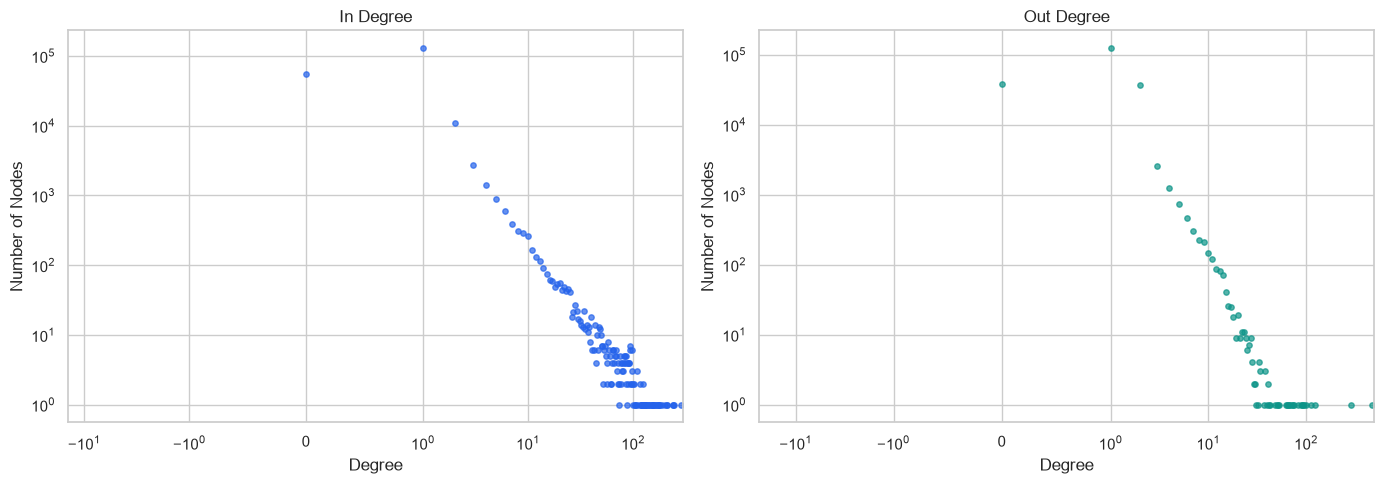

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col, color, ax in [
    ("in_degree", "#2563eb", axes[0]),
    ("out_degree", "#0d9488", axes[1]),
]:
    counts = df[col].value_counts().sort_index()
    ax.scatter(counts.index, counts.values, color=color, alpha=0.7, s=15)
    ax.set_yscale("log")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Degree")
    ax.set_ylabel("Number of Nodes")
plt.tight_layout()
plt.show()

### 6.6 Temporal edge consistency
Check whether any edge connects different time steps. Zero cross-time edges would allow snapshot-level graph partitioning without severing edges. This does not prove that within-snapshot features or topology are available at the moment a transaction occurs.

In [48]:
time_steps = df["time_step"].to_numpy()
src_time = time_steps[src]
dst_time = time_steps[dst]
cross_time_mask = src_time != dst_time
num_cross_time_edges = int(cross_time_mask.sum())

print("Total edges:", len(src))
print("Cross-time-step edges:", num_cross_time_edges)
print("Same-time-step edges:", (~cross_time_mask).sum())
if num_cross_time_edges:
    print("WARNING: investigate cross-time edges before using snapshot-based evaluation.")

Total edges: 234355
Cross-time-step edges: 0
Same-time-step edges: 234355


### 6.7 Degree by class — training period
Compare licit and illicit degree distributions using only labeled training nodes and edges with both endpoints in the training period. Differences may motivate structural features or a degree-stratified evaluation, but do not establish predictive utility. Boxplots hide extreme points for readability; the numerical summary retains them.

in_degree                       out_degree                        \
                mean median       std  max       mean median       std  max   
class_name                                                                    
Illicit     1.190526    1.0  6.699805  173   0.761407    1.0  0.546629    2   
Licit       1.824202    1.0  6.190210  284   1.147129    1.0  3.955697  472   

              degree                        
                mean median       std  max  
class_name                                  
Illicit     1.951933    1.0  6.667237  173  
Licit       2.971331    2.0  7.247691  473

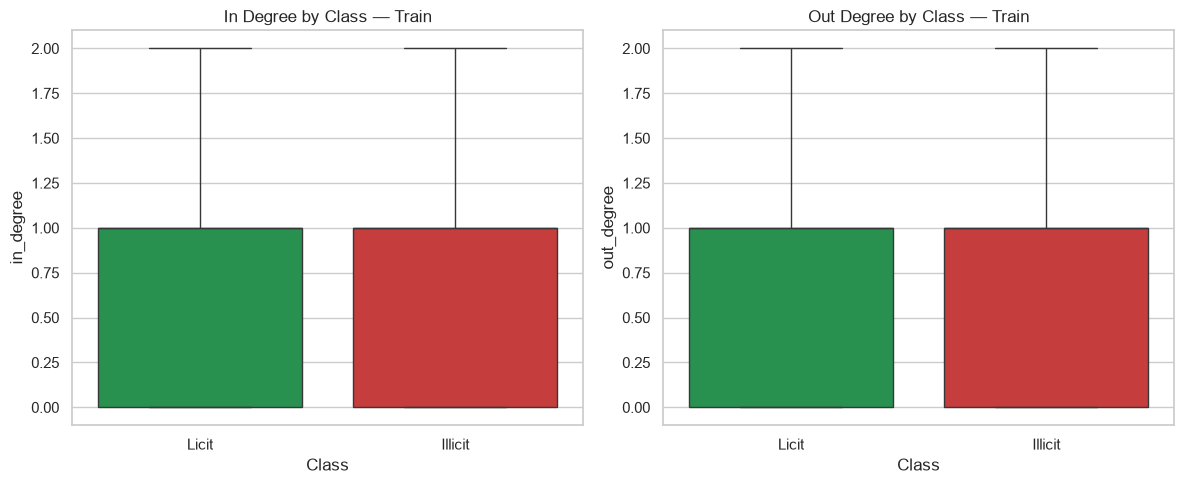

In [49]:
train_edge_mask = (src_time <= 29) & (dst_time <= 29)
train_in_degree = np.bincount(dst[train_edge_mask], minlength=num_nodes)
train_out_degree = np.bincount(src[train_edge_mask], minlength=num_nodes)
train_node_mask = (time_steps <= 29) & (df["label"].to_numpy() != -1)

train_labeled = df.loc[train_node_mask, ["txId", "label"]].copy()
train_labeled["in_degree"] = train_in_degree[train_node_mask]
train_labeled["out_degree"] = train_out_degree[train_node_mask]
train_labeled["degree"] = train_labeled["in_degree"] + train_labeled["out_degree"]
train_labeled["class_name"] = train_labeled["label"].map(class_names)

degree_summary = train_labeled.groupby("class_name")[["in_degree", "out_degree", "degree"]].agg(["mean", "median", "std", "max"])
display(degree_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for col, ax in zip(["in_degree", "out_degree"], axes):
    sns.boxplot(data=train_labeled, x="class_name", y=col, hue="class_name",
                order=["Licit", "Illicit"], hue_order=["Licit", "Illicit"],
                palette={"Licit": "#16a34a", "Illicit": "#dc2626"},
                legend=False, showfliers=False, ax=ax)
    ax.set_title(f"{col.replace('_', ' ').title()} by Class — Train")
    ax.set_xlabel("Class")
plt.tight_layout()
plt.show()

### 6.8 Isolated nodes
Identify nodes with no incoming or outgoing edges in the released graph. Their GNN embeddings cannot receive neighbor messages, although self-information can still support classification. Report label counts for isolated nodes within the training graph only when considering a tabular fallback.

In [50]:
isolated_mask = df["degree"] == 0
num_isolated = int(isolated_mask.sum())
print("Isolated nodes (full graph):", num_isolated)
print(f"Isolated node percentage: {num_isolated / num_nodes:.2%}")
train_isolated_mask = (time_steps <= 29) & ((train_in_degree + train_out_degree) == 0)
print("Isolated nodes (training graph):", int(train_isolated_mask.sum()))
display(df.loc[train_isolated_mask, "label"].map(class_names).value_counts().reindex(["Unknown", "Licit", "Illicit"], fill_value=0))

Isolated nodes (full graph): 0
Isolated node percentage: 0.00%
Isolated nodes (training graph): 0


label
Unknown    0
Licit      0
Illicit    0
Name: count, dtype: int64

### 6.9 Weakly connected components
A weakly connected component is a maximal set of nodes that can reach one another when edge directions are ignored. Ordinary message passing cannot transfer information across disconnected components. Inspect component sizes, including singletons, and plot the largest components.

Weakly connected components: 49
Largest component: 7880
Smallest component: 1089


count      49.000000
mean     4158.551020
std      1592.470592
min      1089.000000
25%      2891.000000
50%      4291.000000
75%      5121.000000
max      7880.000000
Name: count, dtype: float64

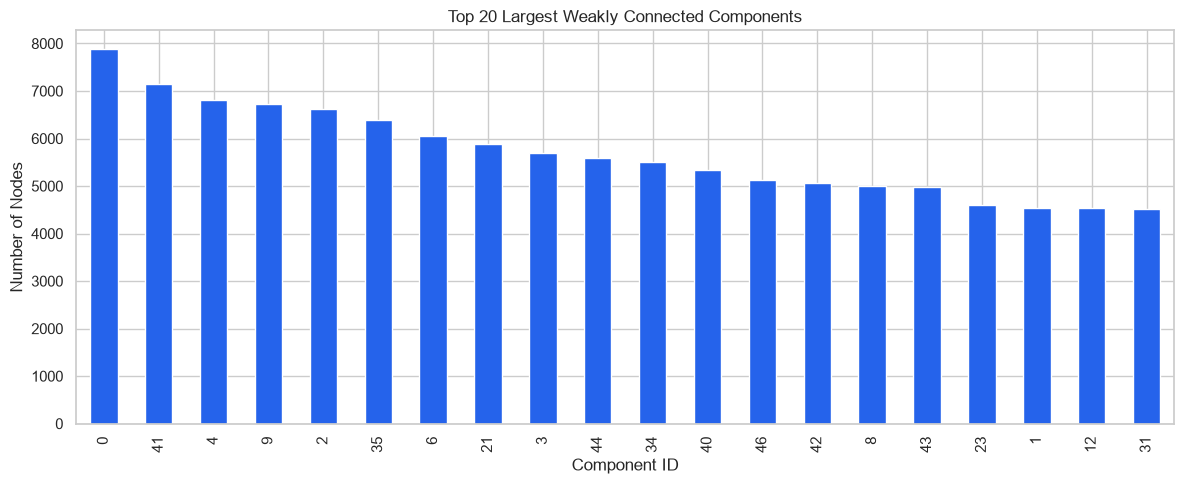

In [51]:
num_components, component_ids = connected_components(
    adj, directed=True, connection="weak", return_labels=True
)
df["component_id"] = component_ids
component_sizes = df["component_id"].value_counts()

assert component_sizes.sum() == num_nodes
print("Weakly connected components:", num_components)
print("Largest component:", component_sizes.max())
print("Smallest component:", component_sizes.min())
display(component_sizes.describe())

plt.figure(figsize=(12, 5))
component_sizes.head(20).plot(kind="bar", color="#2563eb")
plt.title("Top 20 Largest Weakly Connected Components")
plt.xlabel("Component ID")
plt.ylabel("Number of Nodes")
plt.tight_layout()
plt.show()

## 7. Homophily and heterophily

Label homophily measures the tendency for connected nodes to share a label. Standard neighborhood averaging can be useful when neighbor signals are informative, but class agreement alone is neither necessary nor sufficient for successful GNN learning.

### 7.1 Edge homophily — training period
For edges with two known labels in the training graph, compute

$$h = \frac{1}{|E_L|}\sum_{(u,v)\in E_L}\mathbf{1}[y_u=y_v].$$

The complementary fraction $1-h$ is edge heterophily. Report labeled-edge coverage because unknown endpoints are excluded and the measured subset may not be representative of the entire graph.

In [52]:
labels = df["label"].to_numpy()
src_labels = labels[src]
dst_labels = labels[dst]
known_edge_mask = (src_labels != -1) & (dst_labels != -1)
valid_edge_mask = train_edge_mask & known_edge_mask

valid_src_labels = src_labels[valid_edge_mask]
valid_dst_labels = dst_labels[valid_edge_mask]
num_valid_edges = int(valid_edge_mask.sum())
assert num_valid_edges > 0, "No labeled training edges."

homophily = (valid_src_labels == valid_dst_labels).mean()
heterophily = 1 - homophily
labeled_edge_coverage = num_valid_edges / train_edge_mask.sum()

print("Labeled training edges:", num_valid_edges)
print(f"Edge homophily: {homophily:.4f}")
print(f"Edge heterophily: {heterophily:.4f}")
print(f"Labeled edge coverage: {labeled_edge_coverage:.2%}")

Labeled training edges: 20151
Edge homophily: 0.9501
Edge heterophily: 0.0499
Labeled edge coverage: 14.37%


### 7.2 Directed class mixing matrix
Count the four source–destination class combinations and normalize each row to estimate the conditional destination class distribution. A high overall homophily may be dominated by licit-to-licit edges, so inspect illicit-to-illicit and illicit-to-licit edges separately. Rows with no observations have undefined proportions.

Destination,Licit,Illicit
Source,,
Licit,18512,441
Illicit,564,634


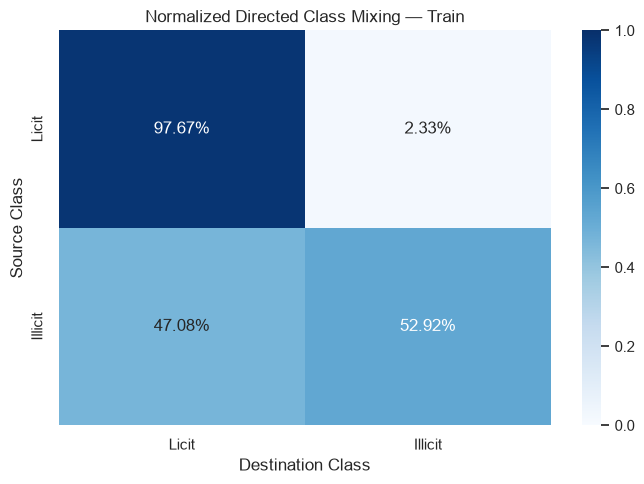

In [53]:
mixing_matrix = pd.crosstab(
    valid_src_labels, valid_dst_labels,
    rownames=["Source"], colnames=["Destination"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
mixing_matrix = mixing_matrix.rename(index=class_names, columns=class_names)
assert mixing_matrix.to_numpy().sum() == num_valid_edges
display(mixing_matrix)

mixing_normalized = mixing_matrix.div(mixing_matrix.sum(axis=1).replace(0, np.nan), axis=0)
plt.figure(figsize=(7, 5))
sns.heatmap(mixing_normalized, annot=True, fmt=".2%", cmap="Blues", vmin=0, vmax=1)
plt.title("Normalized Directed Class Mixing — Train")
plt.xlabel("Destination Class")
plt.ylabel("Source Class")
plt.tight_layout()
plt.show()

### 7.3 Adjusted homophily
Compare observed agreement with an independence baseline that preserves the marginal label proportions at source and destination endpoints:

$$h_{\mathrm{expected}}=\sum_c p_{\mathrm{src}}(c)p_{\mathrm{dst}}(c),\qquad
h_{\mathrm{adj}}=\frac{h-h_{\mathrm{expected}}}{1-h_{\mathrm{expected}}}.$$

Positive adjusted homophily indicates greater agreement than expected, zero indicates agreement at the baseline and negative values indicate less agreement. The statistic is undefined when the expected agreement is one. This is a directed-edge, marginal-adjusted agreement measure; it does not remove label-selection bias.

In [54]:
def homophily_statistics(source_labels, target_labels):
    """Compute raw and adjusted agreement for known binary endpoint labels."""
    n = len(source_labels)
    if n == 0:
        return np.nan, np.nan, np.nan
    counts = np.bincount(2 * source_labels + target_labels, minlength=4).reshape(2, 2)
    observed = np.trace(counts) / n
    source_prob = counts.sum(axis=1) / n
    target_prob = counts.sum(axis=0) / n
    expected = np.dot(source_prob, target_prob)
    adjusted = (observed - expected) / (1 - expected) if not np.isclose(expected, 1) else np.nan
    return observed, expected, adjusted

observed_homophily, expected_homophily, adjusted_homophily = homophily_statistics(valid_src_labels, valid_dst_labels)
assert np.isclose(observed_homophily, homophily)
print(f"Observed homophily: {homophily:.4f}")
print(f"Expected homophily: {expected_homophily:.4f}")
print(f"Adjusted homophily: {adjusted_homophily:.4f}")

Observed homophily: 0.9501
Expected homophily: 0.8935
Adjusted homophily: 0.5315


### 7.4 Homophily over training time steps
Compute raw and adjusted homophily for each training snapshot, along with labeled-edge coverage. Mark undefined values as missing instead of assigning zero. Small labeled-edge counts limit confidence in snapshot-level comparisons. These statistics are for offline research, not features that may use unavailable neighbor labels at inference.

,time_step,homophily,expected_homophily,adjusted_homophily,labeled_edges,label_coverage
0,1,0.992723,0.992731,-0.000966,1924,0.209952
1,2,0.986014,0.986014,0.000000,858,0.163709
2,3,0.988996,0.989022,-0.002413,727,0.087422
3,4,0.990590,0.983870,0.416640,1169,0.142910
4,5,0.997988,0.997988,0.000000,1491,0.172910
5,6,0.995215,0.995215,0.000000,209,0.039870
6,7,0.983683,0.945618,0.699955,858,0.118296
7,8,0.984674,0.966095,0.547979,1044,0.201311
8,9,0.758264,0.724285,0.123243,484,0.081495
9,10,0.985130,0.974254,0.422437,538,0.062646


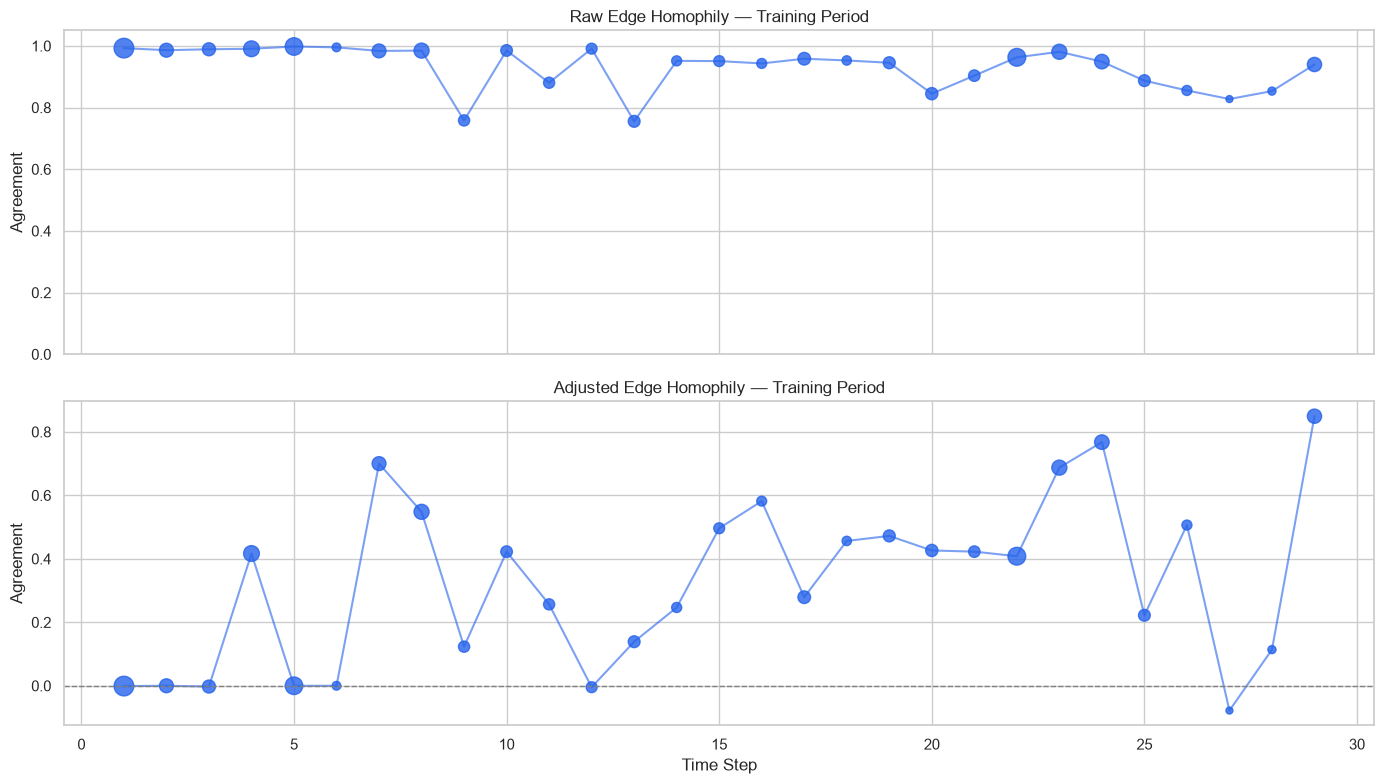

In [55]:
homophily_records = []
for t in range(1, 30):
    snapshot_edges = (src_time == t) & (dst_time == t)
    mask = snapshot_edges & known_edge_mask
    count = int(mask.sum())
    total = int(snapshot_edges.sum())
    observed, expected, adjusted = homophily_statistics(src_labels[mask], dst_labels[mask])
    homophily_records.append({
        "time_step": t,
        "homophily": observed,
        "expected_homophily": expected,
        "adjusted_homophily": adjusted,
        "labeled_edges": count,
        "label_coverage": count / total if total else np.nan,
    })

homophily_df = pd.DataFrame(homophily_records)
display(homophily_df)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, col, title in [
    (axes[0], "homophily", "Raw Edge Homophily"),
    (axes[1], "adjusted_homophily", "Adjusted Edge Homophily"),
]:
    ax.plot(homophily_df["time_step"], homophily_df[col], color="#2563eb", alpha=0.6)
    valid = homophily_df.dropna(subset=[col])
    sizes = 20 + 180 * valid["labeled_edges"] / max(1, homophily_df["labeled_edges"].max())
    ax.scatter(valid["time_step"], valid[col], s=sizes, color="#2563eb", alpha=0.8)
    ax.set_title(title + " — Training Period")
    ax.set_ylabel("Agreement")
axes[0].set_ylim(0, 1.05)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Time Step")
plt.tight_layout()
plt.show()

## 8. Research findings
### 8.1 Reproducible summary
The following cell consolidates the EDA measurements so the graph findings can be recorded using actual computed values rather than hypothetical results.

In [56]:
eda_summary = pd.Series({
    "Transactions": num_nodes,
    "Directed edges": len(src),
    "Unlabeled nodes": int((labels == -1).sum()),
    "Licit-to-illicit ratio (all labeled nodes)": round(imbalance_ratio, 4),
    "Highly correlated training feature pairs": len(high_corr_pairs),
    "Cross-time-step edges": num_cross_time_edges,
    "Isolated nodes (full graph)": num_isolated,
    "Weakly connected components": num_components,
    "Largest weak component": int(component_sizes.max()),
    "Labeled training edges": num_valid_edges,
    "Labeled training edge coverage": round(labeled_edge_coverage, 4),
    "Training edge homophily": round(homophily, 4),
    "Training adjusted homophily": round(adjusted_homophily, 4),
}, name="Value")
display(eda_summary.to_frame())
display(mixing_matrix)

,Value
Transactions,203769.0000
Directed edges,234355.0000
Unlabeled nodes,157205.0000
Licit-to-illicit ratio (all labeled nodes),9.2451
Highly correlated training feature pairs,104.0000
Cross-time-step edges,0.0000
Isolated nodes (full graph),0.0000
Weakly connected components,49.0000
Largest weak component,7880.0000
Labeled training edges,20151.0000


Destination,Licit,Illicit
Source,,
Licit,18512,441
Illicit,564,634


### 8.2 Implications for model development

| EDA observation | Proposed experiment |
|---|---|
| Severe class imbalance | Compare weighted losses and class-aware evaluation metrics. |
| Different observed label proportions across periods | Use chronological evaluation and report metrics over time. |
| Correlated or pre-aggregated features | Compare local-only versus full-feature baselines; investigate feature ablation. |
| Isolated or low-degree nodes, if common | Compare tabular and GNN performance by degree. |
| Class mixing or adjusted agreement, once measured | Test whether directed or heterophily-aware aggregation adds predictive value. |
| Variable homophily across snapshots, if observed | Investigate temporal robustness and graph-reliability-aware fusion. |

These are hypotheses and experimental motivations, not evidence that a particular architecture will outperform another. The GraphTrust-XGB gate, if developed, must rely on inference-available signals rather than unknown or future labels.

### 8.3 Dataset limitations and leakage considerations

- Unknown labels are not equivalent to licit labels; labeled-edge statistics can suffer from selection bias.
- The anonymized features include precomputed neighborhood statistics. Their availability at transaction time and the scope of the original normalization cannot be established from this notebook alone.
- A chronological split and zero cross-time edges (if confirmed) do not rule out within-snapshot look-ahead. Snapshot-level offline detection must be distinguished from real-time transaction scoring.
- Do not use `txId`, target labels, split indicators or component identifiers as default numeric model inputs. Any structural features used later must be computed from the permitted graph at prediction time.
- Test summaries already visible in this notebook are descriptive only; keep the held-out test period fixed and do not tune models against it.